# Implementación de Polars
# Ejemplos Varios<a class="tocSkip">
## Reconocimiento de Patrones <a class="tocSkip">
### Ingenieria Electrónica <a class="tocSkip">
### Universidad Popular del Cesar <a class="tocSkip">
### Prof.: Jose Ramón Iglesias Gamarra - [https://github.com/joseramoniglesias/](https://github.com/joseramoniglesias/) <a class="tocSkip">
  **joseiglesias@unicesar.edu.co**

# Librerías
Estas son las librerías utilizadas en (entorno Python):

# Datos
Vamos a utilizar datos públicos del sistema nacional de salud de Inglaterra (NHS: National Health Service). El archivo de tipo csv contiene una muestra de datos de prescripciones médicas realizadas en Reino Unido (Deciembre 2014).

Polars puede trabajar con distintos formatos de datos (csv, parquet, json, DBs, etc.).

In [1]:
import polars as pl
from datetime import datetime

In [2]:
# Lectura de datos (csv)
# ==============================================================================
nhs_raw_df = pl.read_csv('sample_epd_201412.csv', separator=";")
print(f"Tipo de objeto: {type(nhs_raw_df)}")
print(f"Dimensiones de los datos: {nhs_raw_df.shape}")
display(nhs_raw_df.head())

Tipo de objeto: <class 'polars.dataframe.frame.DataFrame'>
Dimensiones de los datos: (50000, 26)


YEAR_MONTH,REGIONAL_OFFICE_NAME,REGIONAL_OFFICE_CODE,AREA_TEAM_NAME,AREA_TEAM_CODE,PCO_NAME,PCO_CODE,PRACTICE_NAME,PRACTICE_CODE,ADDRESS_1,ADDRESS_2,ADDRESS_3,ADDRESS_4,POSTCODE,BNF_CHEMICAL_SUBSTANCE,CHEMICAL_SUBSTANCE_BNF_DESCR,BNF_CODE,BNF_DESCRIPTION,BNF_CHAPTER_PLUS_CODE,QUANTITY,ITEMS,TOTAL_QUANTITY,ADQUSAGE,NIC,ACTUAL_COST,UNIDENTIFIED
i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,i64,f64,f64,f64,f64,str
201412,"""NORTH OF ENGLAND""","""Y54""","""GREATER MANCHESTER AREA""","""Q46""","""OLDHAM CCG""","""00Y00""","""ADDY PRACTICE""","""P85603""","""BARLEY CLOUGH MEDICAL CTR""","""NUGGET STREET""","""OLDHAM""",null,"""OL4 1BN""","""0902012H0""","""Oral rehydration salts""","""0902012H0BBAGAE""","""Dioralyte oral powder sachets …","""09: Nutrition and Blood""",12.0,1,12.0,3.0,4.5,4.16564,"""N"""
201412,"""NORTH OF ENGLAND""","""Y54""","""WEST YORKSHIRE AREA""","""Q52""","""LEEDS NORTH CCG""","""02V00""","""ALLERTON MEDICAL CENTRE""","""B86039""","""ALLERTON MEDICAL CENTRE""","""6 MONTREAL AVENUE""","""LEEDS""","""WEST YORKSHIRE""","""LS7 4LF""","""1103010C0""","""Chloramphenicol""","""1103010C0AAADAD""","""Chloramphenicol 1% eye ointmen…","""11: Eye""",4.0,5,20.0,0.0,8.8,8.1839,"""N"""
201412,"""SOUTH OF ENGLAND""","""Y57""","""SURREY AND SUSSEX AREA""","""Q68""","""CRAWLEY CCG""","""09H00""","""SAXONBROOK MEDICAL CENTRE""","""H82026""","""SAXONBROOK MEDICAL CENTRE""","""MAIDENBOWER SQUARE""","""CRAWLEY""","""WEST SUSSEX""","""RH10 7QH""","""0703010F0""","""Combined ethinylestradiol 30mc…","""0703010F0BEABAH""","""Microgynon 30 ED tablets""","""07: Obstetrics, Gynaecology an…",84.0,3,252.0,0.0,8.97,8.3532,"""N"""
201412,"""LONDON""","""Y56""","""NORTH EAST LONDON AREA""","""Q61""","""REDBRIDGE CCG""","""08N00""","""THE PALMS MEDICAL CENTRE""","""F86009""","""THE PALMS MEDICAL CENTRE""","""97-101 NETLEY ROAD""","""NEWBURY PARK""","""ILFORD, ESSEX""","""IG2 7NW""","""131002030""","""Terbinafine hydrochloride""","""131002030AAAAAA""","""Terbinafine 1% cream""","""13: Skin""",30.0,4,120.0,0.0,14.0,12.9708,"""N"""
201412,"""SOUTH OF ENGLAND""","""Y57""","""BRISTOL, N SOM, SOM & S GLOS A…","""Q65""","""BRISTOL CCG""","""11H00""","""SOUTHMEAD & HENBURY FAMILY PRA…","""L81067""","""SOUTHMEAD HEALTH CENTRE""","""ULLSWATER ROAD,SOUTHMEAD""","""BRISTOL""",null,"""BS10 6DF""","""0206030N0""","""Nicorandil""","""0206030N0AAAAAA""","""Nicorandil 10mg tablets""","""02: Cardiovascular System""",10.0,71,710.0,177.5,46.86,51.2295,"""N"""


In [3]:
n_chars = 50

# df.columns
# ==============================================================================
print("="*n_chars)
print("df.columns: listado de columnas de un DataFrame")
print(nhs_raw_df.columns)
print("")

# df.types
# ==============================================================================
print("="*n_chars)
print("df.types: tipos de datos de las columnas de un DataFrame")
print(nhs_raw_df.dtypes)
print(f"Tipos de datos únicos: {set(nhs_raw_df.dtypes)}")
print("")

# df.schema
# ==============================================================================
print("="*n_chars)
print("df.schema: Diccionario con las columnas y sus tipos de datos")
print(nhs_raw_df.schema)
print("")

# df.shape
# ==============================================================================
print("="*n_chars)
print("df.shape : filas x columnas de un DataFrame")
print(nhs_raw_df.shape)
print("")

# df.height
# ==============================================================================
print("="*n_chars)
print("df.height : número de filas de un DataFrame")
print(nhs_raw_df.height)
print("")

# df.width
# ==============================================================================
print("="*n_chars)
print("df.width : número de columnas de un DataFrame")
print(nhs_raw_df.width)
print("")

df.columns: listado de columnas de un DataFrame
['YEAR_MONTH', 'REGIONAL_OFFICE_NAME', 'REGIONAL_OFFICE_CODE', 'AREA_TEAM_NAME', 'AREA_TEAM_CODE', 'PCO_NAME', 'PCO_CODE', 'PRACTICE_NAME', 'PRACTICE_CODE', 'ADDRESS_1', 'ADDRESS_2', 'ADDRESS_3', 'ADDRESS_4', 'POSTCODE', 'BNF_CHEMICAL_SUBSTANCE', 'CHEMICAL_SUBSTANCE_BNF_DESCR', 'BNF_CODE', 'BNF_DESCRIPTION', 'BNF_CHAPTER_PLUS_CODE', 'QUANTITY', 'ITEMS', 'TOTAL_QUANTITY', 'ADQUSAGE', 'NIC', 'ACTUAL_COST', 'UNIDENTIFIED']

df.types: tipos de datos de las columnas de un DataFrame
[Int64, String, String, String, String, String, String, String, String, String, String, String, String, String, String, String, String, String, String, Float64, Int64, Float64, Float64, Float64, Float64, String]
Tipos de datos únicos: {Float64, Int64, String}

df.schema: Diccionario con las columnas y sus tipos de datos
Schema({'YEAR_MONTH': Int64, 'REGIONAL_OFFICE_NAME': String, 'REGIONAL_OFFICE_CODE': String, 'AREA_TEAM_NAME': String, 'AREA_TEAM_CODE': String, 'PC

In [4]:
# df.describe()
# ==============================================================================
print("df.describe(): Summary Stats")
display(nhs_raw_df.describe())

df.describe(): Summary Stats


statistic,YEAR_MONTH,REGIONAL_OFFICE_NAME,REGIONAL_OFFICE_CODE,AREA_TEAM_NAME,AREA_TEAM_CODE,PCO_NAME,PCO_CODE,PRACTICE_NAME,PRACTICE_CODE,ADDRESS_1,ADDRESS_2,ADDRESS_3,ADDRESS_4,POSTCODE,BNF_CHEMICAL_SUBSTANCE,CHEMICAL_SUBSTANCE_BNF_DESCR,BNF_CODE,BNF_DESCRIPTION,BNF_CHAPTER_PLUS_CODE,QUANTITY,ITEMS,TOTAL_QUANTITY,ADQUSAGE,NIC,ACTUAL_COST,UNIDENTIFIED
str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,str
"""count""",50000.0,"""50000""","""50000""","""50000""","""50000""","""50000""","""50000""","""50000""","""50000""","""49976""","""47415""","""48889""","""42708""","""49978""","""50000""","""50000""","""50000""","""50000""","""50000""",50000.0,50000.0,50000.0,50000.0,50000.0,50000.0,"""50000"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""24""","""2585""","""1111""","""7292""","""22""","""0""","""0""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,"""0"""
"""mean""",201412.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,158.800484,5.0597,411.319542,120.445982,41.311326,38.300054,null
"""std""",0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,998.722709,16.986033,1836.927548,645.331458,112.181317,103.600127,null
"""min""",201412.0,"""LONDON""","""-""","""ARDEN,HEREFORDS & WORCESTER AR…","""-""","""ADDACTION""","""-""","""(FRACTURE CLINIC) NORTH OOH""","""-""","""-""","""& WELLBEING,EXMOOR STREET""","""(OFF SOUTH HILL PARK)""","""-""","""-""","""0101010G0""","""Acamprosate calcium""","""0101010G0AAABAB""","""3M Micropore Silicone tape 5cm""","""01: Gastro-Intestinal System""",0.5,1.0,0.5,0.0,0.01,0.06461,"""N"""
"""25%""",201412.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,20.0,1.0,30.0,0.0,4.98,4.71941,null
"""50%""",201412.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,56.0,2.0,84.0,9.33333,12.65,11.86299,null
"""75%""",201412.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,100.0,4.0,224.0,56.0,35.97,33.23834,null
"""max""",201412.0,"""UNIDENTIFIED""","""Y57""","""WEST YORKSHIRE AREA""","""Q70""","""YORK TEACHING HOSPITAL NHS FT""","""RYY00""","""ZETLAND MEDICAL PRACTICE""","""Y04837""","""YPRES ROAD""","""ZACHARY MERTON HOSPITAL""","""YORKLEY,LYDNEY""","""YORKSHIRE""","""YO8 9BX""","""2396""","""Zuclopenthixol hydrochloride""","""23965609646""","""palmdoc iCare Advanced testing…","""23: Stoma Appliances""",45000.0,1152.0,115200.0,43007.99999,7256.56,6698.14673,"""Y"""


In [5]:
# df.null_count()
# ==============================================================================
print("df.null_count(): Devuelve un DataFrame con el total de valores nulos por columna")
display(nhs_raw_df.null_count())

df.null_count(): Devuelve un DataFrame con el total de valores nulos por columna


YEAR_MONTH,REGIONAL_OFFICE_NAME,REGIONAL_OFFICE_CODE,AREA_TEAM_NAME,AREA_TEAM_CODE,PCO_NAME,PCO_CODE,PRACTICE_NAME,PRACTICE_CODE,ADDRESS_1,ADDRESS_2,ADDRESS_3,ADDRESS_4,POSTCODE,BNF_CHEMICAL_SUBSTANCE,CHEMICAL_SUBSTANCE_BNF_DESCR,BNF_CODE,BNF_DESCRIPTION,BNF_CHAPTER_PLUS_CODE,QUANTITY,ITEMS,TOTAL_QUANTITY,ADQUSAGE,NIC,ACTUAL_COST,UNIDENTIFIED
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,24,2585,1111,7292,22,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
# .select(): Método utilizado para seleccionar una o más columnas
# ==============================================================================
nhs_raw_df.select(pl.col("REGIONAL_OFFICE_NAME"))

REGIONAL_OFFICE_NAME
str
"""NORTH OF ENGLAND"""
"""NORTH OF ENGLAND"""
"""SOUTH OF ENGLAND"""
"""LONDON"""
"""SOUTH OF ENGLAND"""
…
"""MIDLANDS AND EAST OF ENGLAND"""
"""LONDON"""
"""SOUTH OF ENGLAND"""


In [7]:
type(nhs_raw_df.select(pl.col("REGIONAL_OFFICE_NAME")))

polars.dataframe.frame.DataFrame

In [8]:
nhs_raw_df.select(
    [
        pl.col("REGIONAL_OFFICE_NAME"),
        pl.col("REGIONAL_OFFICE_CODE"),
    ]
)

REGIONAL_OFFICE_NAME,REGIONAL_OFFICE_CODE
str,str
"""NORTH OF ENGLAND""","""Y54"""
"""NORTH OF ENGLAND""","""Y54"""
"""SOUTH OF ENGLAND""","""Y57"""
"""LONDON""","""Y56"""
"""SOUTH OF ENGLAND""","""Y57"""
…,…
"""MIDLANDS AND EAST OF ENGLAND""","""Y55"""
"""LONDON""","""Y56"""
"""SOUTH OF ENGLAND""","""Y57"""


In [9]:
# Selección de una única columna
# ==============================================================================
display(nhs_raw_df.select("REGIONAL_OFFICE_NAME").head())

# Selección de múltiples columnas
# ==============================================================================
display(nhs_raw_df.select(["REGIONAL_OFFICE_NAME","REGIONAL_OFFICE_CODE"]).head())

REGIONAL_OFFICE_NAME
str
"""NORTH OF ENGLAND"""
"""NORTH OF ENGLAND"""
"""SOUTH OF ENGLAND"""
"""LONDON"""
"""SOUTH OF ENGLAND"""


REGIONAL_OFFICE_NAME,REGIONAL_OFFICE_CODE
str,str
"""NORTH OF ENGLAND""","""Y54"""
"""NORTH OF ENGLAND""","""Y54"""
"""SOUTH OF ENGLAND""","""Y57"""
"""LONDON""","""Y56"""
"""SOUTH OF ENGLAND""","""Y57"""


In [10]:
# 1. Seleccionar y renombrar columnas: "REGIONAL_OFFICE_NAME", "AREA_TEAM_NAME", "BNF_DESCRIPTION", "TOTAL_QUANTITY", "NIC"
# ==============================================================================
processed_df = (
    nhs_raw_df
    .select(
        [
            pl.col("REGIONAL_OFFICE_NAME").alias("region_name"),
            pl.col("AREA_TEAM_NAME").alias("area_name"),
            pl.col("BNF_DESCRIPTION").alias("drug_name"),
            pl.col("TOTAL_QUANTITY").alias("total_qt"),
            pl.col("NIC").alias("net_ingredient_cost"),
        ]
    )
)

processed_df.head()

region_name,area_name,drug_name,total_qt,net_ingredient_cost
str,str,str,f64,f64
"""NORTH OF ENGLAND""","""GREATER MANCHESTER AREA""","""Dioralyte oral powder sachets …",12.0,4.5
"""NORTH OF ENGLAND""","""WEST YORKSHIRE AREA""","""Chloramphenicol 1% eye ointmen…",20.0,8.8
"""SOUTH OF ENGLAND""","""SURREY AND SUSSEX AREA""","""Microgynon 30 ED tablets""",252.0,8.97
"""LONDON""","""NORTH EAST LONDON AREA""","""Terbinafine 1% cream""",120.0,14.0
"""SOUTH OF ENGLAND""","""BRISTOL, N SOM, SOM & S GLOS A…","""Nicorandil 10mg tablets""",710.0,46.86


In [11]:
# 2. Creación de nuevas columnas: unit_cost, execution_date
# ==============================================================================
processed_df = (
    processed_df
    .with_columns([
        (pl.col("net_ingredient_cost")/pl.col("total_qt")).alias("unit_cost"),
        (pl.lit(datetime.now().date()).alias("execution_date")),
    ])
)

processed_df.head()

region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""NORTH OF ENGLAND""","""GREATER MANCHESTER AREA""","""Dioralyte oral powder sachets …",12.0,4.5,0.375,2026-10-10
"""NORTH OF ENGLAND""","""WEST YORKSHIRE AREA""","""Chloramphenicol 1% eye ointmen…",20.0,8.8,0.44,2026-10-10
"""SOUTH OF ENGLAND""","""SURREY AND SUSSEX AREA""","""Microgynon 30 ED tablets""",252.0,8.97,0.035595,2026-10-10
"""LONDON""","""NORTH EAST LONDON AREA""","""Terbinafine 1% cream""",120.0,14.0,0.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BRISTOL, N SOM, SOM & S GLOS A…","""Nicorandil 10mg tablets""",710.0,46.86,0.066,2026-10-10


In [12]:
# 3. Filtrar filas: region_name = 'LONDON' or  'SOUTH OF ENGLAND'
# ==============================================================================
processed_df = (
    processed_df
    .filter(
        (pl.col("region_name") == "LONDON") | (pl.col("region_name") == "SOUTH OF ENGLAND")
    )
)

processed_df.head()

region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""SOUTH OF ENGLAND""","""SURREY AND SUSSEX AREA""","""Microgynon 30 ED tablets""",252.0,8.97,0.035595,2026-10-10
"""LONDON""","""NORTH EAST LONDON AREA""","""Terbinafine 1% cream""",120.0,14.0,0.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BRISTOL, N SOM, SOM & S GLOS A…","""Nicorandil 10mg tablets""",710.0,46.86,0.066,2026-10-10
"""SOUTH OF ENGLAND""","""DEVON,CORNWALL&ISLES OF SCILLY…","""Bisoprolol 5mg tablets""",1568.0,55.44,0.035357,2026-10-10
"""SOUTH OF ENGLAND""","""WESSEX AREA""","""Enalapril 20mg tablets""",168.0,6.96,0.041429,2026-10-10


In [13]:
# 4. Ordenar resultados: net_ingredient_cost desc
# ==============================================================================
processed_df = (processed_df.sort("net_ingredient_cost", descending=True))

processed_df.head()

region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Prevenar 13 vacc inj 0.5ml pre…",77.0,3780.7,49.1,2026-10-10
"""LONDON""","""NORTH WEST LONDON AREA""","""Influenza vaccine (split virio…",492.0,3242.28,6.59,2026-10-10
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Tiotropium bromide 18microgram…",2340.0,2613.0,1.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Seretide 500 Accuhaler""",62.0,2537.04,40.92,2026-10-10
"""SOUTH OF ENGLAND""","""WESSEX AREA""","""Fluticasone 250mcg/dose / Salm…",42.0,2498.16,59.48,2026-10-10


In [14]:
# Función de preprocesado
# ==============================================================================
def preprocess_raw_data(raw_data):

    df = (
        raw_data
        .select(
            [
                pl.col("REGIONAL_OFFICE_NAME").alias("region_name"),
                pl.col("AREA_TEAM_NAME").alias("area_name"),
                pl.col("BNF_DESCRIPTION").alias("drug_name"),
                pl.col("TOTAL_QUANTITY").alias("total_qt"),
                pl.col("NIC").alias("net_ingredient_cost"),
            ]
        )
        .with_columns([
            (pl.col("net_ingredient_cost")/pl.col("total_qt")).alias("unit_cost"),
            (pl.lit(datetime.now().date()).alias("execution_date")),
        ])
        .filter(
            (pl.col("region_name") == "LONDON") | (pl.col("region_name") == "SOUTH OF ENGLAND")
        )
        .sort("net_ingredient_cost", descending=True)
    )

    return df

nhs_processed_df = preprocess_raw_data(raw_data=nhs_raw_df)

print(nhs_processed_df.shape)
display(nhs_processed_df.head())

(19181, 7)


region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Prevenar 13 vacc inj 0.5ml pre…",77.0,3780.7,49.1,2026-10-10
"""LONDON""","""NORTH WEST LONDON AREA""","""Influenza vaccine (split virio…",492.0,3242.28,6.59,2026-10-10
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Tiotropium bromide 18microgram…",2340.0,2613.0,1.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Seretide 500 Accuhaler""",62.0,2537.04,40.92,2026-10-10
"""SOUTH OF ENGLAND""","""WESSEX AREA""","""Fluticasone 250mcg/dose / Salm…",42.0,2498.16,59.48,2026-10-10


In [15]:
lazy_nhs_raw_df = nhs_raw_df.lazy()
print(f"Object type: {type(lazy_nhs_raw_df)}")

Object type: <class 'polars.lazyframe.frame.LazyFrame'>


In [16]:
print(lazy_nhs_raw_df)

naive plan: (run LazyFrame.explain(optimized=True) to see the optimized plan)

DF ["YEAR_MONTH", "REGIONAL_OFFICE_NAME", "REGIONAL_OFFICE_CODE", "AREA_TEAM_NAME", ...]; PROJECT */26 COLUMNS


In [17]:
lazy_nhs_processed_df = preprocess_raw_data(raw_data=lazy_nhs_raw_df)
lazy_nhs_processed_df

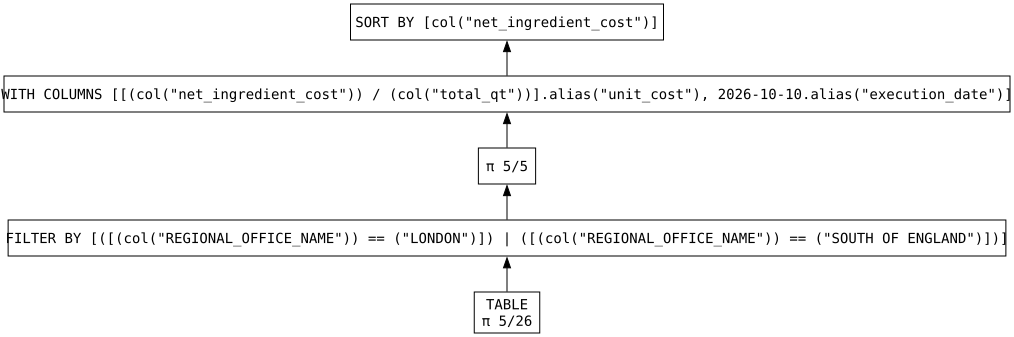

In [18]:
lazy_nhs_processed_df.show_graph(optimized=True)

In [22]:
# .fetch(): devuelve un número limitado de líneas para hacer debugging
# ==============================================================================
print(type(lazy_nhs_processed_df.collect()))
lazy_nhs_processed_df.collect()

<class 'polars.dataframe.frame.DataFrame'>


region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Prevenar 13 vacc inj 0.5ml pre…",77.0,3780.7,49.1,2026-10-10
"""LONDON""","""NORTH WEST LONDON AREA""","""Influenza vaccine (split virio…",492.0,3242.28,6.59,2026-10-10
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Tiotropium bromide 18microgram…",2340.0,2613.0,1.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Seretide 500 Accuhaler""",62.0,2537.04,40.92,2026-10-10
"""SOUTH OF ENGLAND""","""WESSEX AREA""","""Fluticasone 250mcg/dose / Salm…",42.0,2498.16,59.48,2026-10-10
…,…,…,…,…,…,…
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Amlodipine 10mg tablets""",1.0,0.04,0.04,2026-10-10
"""SOUTH OF ENGLAND""","""SURREY AND SUSSEX AREA""","""Folic acid 5mg tablets""",1.0,0.04,0.04,2026-10-10
"""SOUTH OF ENGLAND""","""DEVON,CORNWALL&ISLES OF SCILLY…","""Lisinopril 20mg tablets""",1.0,0.04,0.04,2026-10-10


In [23]:
# .collect(): devuelve todo el DataFrame
# ==============================================================================
print(type(lazy_nhs_processed_df.collect()))
lazy_nhs_processed_df.collect()

<class 'polars.dataframe.frame.DataFrame'>


region_name,area_name,drug_name,total_qt,net_ingredient_cost,unit_cost,execution_date
str,str,str,f64,f64,f64,date
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Prevenar 13 vacc inj 0.5ml pre…",77.0,3780.7,49.1,2026-10-10
"""LONDON""","""NORTH WEST LONDON AREA""","""Influenza vaccine (split virio…",492.0,3242.28,6.59,2026-10-10
"""SOUTH OF ENGLAND""","""THAMES VALLEY AREA""","""Tiotropium bromide 18microgram…",2340.0,2613.0,1.116667,2026-10-10
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Seretide 500 Accuhaler""",62.0,2537.04,40.92,2026-10-10
"""SOUTH OF ENGLAND""","""WESSEX AREA""","""Fluticasone 250mcg/dose / Salm…",42.0,2498.16,59.48,2026-10-10
…,…,…,…,…,…,…
"""SOUTH OF ENGLAND""","""BATH,GLOS,SWINDON & WILTSHIRE …","""Amlodipine 10mg tablets""",1.0,0.04,0.04,2026-10-10
"""SOUTH OF ENGLAND""","""SURREY AND SUSSEX AREA""","""Folic acid 5mg tablets""",1.0,0.04,0.04,2026-10-10
"""SOUTH OF ENGLAND""","""DEVON,CORNWALL&ISLES OF SCILLY…","""Lisinopril 20mg tablets""",1.0,0.04,0.04,2026-10-10


In [25]:
# Group by Operation
# ==============================================================================
agg_df = (
    lazy_nhs_processed_df
    .group_by(["region_name"])
    .agg(
        [
            pl.col("net_ingredient_cost").sum().alias("total_sales"),
            pl.col("total_qt").mean().alias("avg_qt"),
        ]
    )
    .sort("total_sales", descending=True)

).collect()

agg_df

region_name,total_sales,avg_qt
str,f64,f64
"""SOUTH OF ENGLAND""",523946.91,427.324624
"""LONDON""",250269.3,351.671161


**Copyright**

The notebooks are provided as [Open Educational Resource](https://de.wikipedia.org/wiki/Open_Educational_Resources). Feel free to use the notebooks for your own educational purposes. The text is licensed under [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/), the code of the IPython examples under the [MIT license](https://opensource.org/licenses/MIT).